# 线性代数 ― linalg 模块

## 本章要学什么

NumPy 与 SciPy 都有线性代数的模块 `linalg`，其中 SciPy 的函数更多，也能更细致地控制各种分解，这一章用例子确认其中最常用的计算。

- 解线性方程组(`solve()`，以及 `lu_factor()` 与 `lu_solve()`)
- 求最小二乘解(`lstsq()`)
- 特征值与特征向量(`eig()`)，以及广义特征值
- 奇异值分解(`svd()`)与图像压缩

下面会看到，同样一个计算，比起先求逆矩阵再相乘，先做分解再求解既快又准。

In [1]:
from matplotlib import pyplot as plt

import helper.magics
import helper.matplotlib
import numpy as np
from scipy import linalg

## 解线性方程组

`numpy.linalg.solve(A, b)` 与 `scipy.linalg.solve(A, b)` 用来解线性方程组 $\mathbf{A} \mathbf{x} = \mathbf{b}$，也就是计算 $\mathbf{x}=\mathbf{A}^{-1} \mathbf{b}$，其中 $\mathbf{A}$ 是 $m \times m$ 的方阵，$\mathbf{x}$ 与 $\mathbf{b}$ 是长度为 $m$ 的向量。

当 $\mathbf{A}$ 不变而有多个 $\mathbf{b}$ 时，可以把 $m \times n$ 的矩阵 $\mathbf{B}$ 作为第 2 个参数传进去，结果的 $\mathbf{X}$ 也是 $m \times n$，相当于算了 $\mathbf{A}^{-1} \mathbf{B}$。

像 $\mathbf{A}^{-1} \mathbf{B}$ 这样的计算很常见，而 `solve(A, B)` 能一次算完，比先求逆再相乘要快；矩阵小的时候差别不大，矩阵一大差距就拉开了。下面的程序比较两种做法的速度。

In [2]:
m, n = 500, 50
A = np.random.rand(m, m)
B = np.random.rand(m, n)

solution_solve = linalg.solve(A, B)          # 分解之后求解
solution_inv = np.dot(linalg.inv(A), B)      # 求逆矩阵再相乘
print(np.allclose(solution_solve, solution_inv))

%timeit linalg.solve(A, B)
%timeit np.dot(linalg.inv(A), B)

True


16 ms ± 1.51 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


16.6 ms ± 254 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


有时 $\mathbf{B}$ 没法合并成一个矩阵，例如一边依次做出 $\mathbf{B}$、$\mathbf{C}$、$\mathbf{D}$，一边计算 $\mathbf{A}^{-1} \mathbf{B}$、$\mathbf{A}^{-1} \mathbf{C}$、$\mathbf{A}^{-1} \mathbf{D}$，这种情况就要用 `lu_factor()` 与 `lu_solve()`。

先用 `lu_factor(A)` 对 $\mathbf{A}$ 做 LU 分解，得到(LU 矩阵, 重排信息)这样的元组；再把这个元组传给 `lu_solve()`，就不必重新分解 $\mathbf{A}$，能立刻得到对应各个 $\mathbf{B}$ 的解。

In [3]:
lu_pivot = linalg.lu_factor(A)
X3 = linalg.lu_solve(lu_pivot, B)
np.allclose(solution_solve, X3)

True

比较两种做法：用 `inv()` 求逆再相乘，以及用 `lu_factor()` 分解后用 `lu_solve()` 求解。这里把分解所花的时间与每次求解所花的时间分开来测。

In [4]:
M, N = 1000, 100
np.random.seed(0)
A = np.random.rand(M, M)
B = np.random.rand(M, N)

Ai = linalg.inv(A)
lu_pivot = linalg.lu_factor(A)
%timeit linalg.inv(A)
%timeit Ai @ B
%timeit linalg.lu_factor(A)
%timeit linalg.lu_solve(lu_pivot, B)

80.9 ms ± 627 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


2.39 ms ± 69.4 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


29.7 ms ± 1.19 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


4.19 ms ± 24.1 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


`inv()` 把分解与求逆一起做完，所以比 `lu_factor()` 更费时间；而 `lu_solve()` 与矩阵乘积的速度差不多。

## 最小二乘解

`lstsq()` 比 `solve()` 更一般，$\mathbf{A}$ 不是方阵也能用：方程的个数比未知数少、相等或者更多都可以。它返回使 $\left \| \mathbf{b}-\mathbf{A} \cdot \mathbf{x} \right \|$ 最小的 $\mathbf{x}$，这个 $\mathbf{x}$ 称为最小二乘解，它让所有式子的误差平方和最小。

作为例子，这里解离散卷积的逆运算。把信号 $\mathbf{x}$ 输入离散线性时不变系统 $\mathbf{h}$，输出 $\mathbf{y}$ 就是卷积 $\mathbf{y} = \mathbf{x} * \mathbf{h}$，式子如下。

$$y[n] = \sum h[m]\ x[n-m]$$

若 $\mathbf{h}$ 的长度是 $n$、$\mathbf{x}$ 的长度是 $m$，则 $\mathbf{y}$ 的长度是 $n+m-1$，各个值按下面这样计算。

```text
y[0] = h[0]*x[0]
y[1] = h[0]*x[1] + h[1]*x[0]
y[2] = h[0]*x[2] + h[1]*x[1] + h[2]*x[0]
y[3] = h[0]*x[3] + h[1]*x[2] + h[2]*x[1]
...
y[n+m-1] = h[n-1]*x[m-1]
```

卷积的逆运算就是由 $\mathbf{x}$ 与 $\mathbf{y}$ 求出 $\mathbf{h}$：设 $\mathbf{h}$ 的长度为 $n$，则未知数有 $n$ 个，而式子有 $n+m-1$ 个，式子比未知数多，所以一般没有完全精确的解，只能去找让 $\mathbf{x} * \mathbf{h}$ 与 $\mathbf{y}$ 误差最小的 $\mathbf{h}$，这就是最小二乘解。

下面的程序用 `lstsq()` 计算卷积的逆运算。

❶ `make_data()` 用标准正态分布的随机数生成 $\mathbf{x}$ 与 $\mathbf{h}$，其中 $\mathbf{h}$ 在实际系统里是不知道的，取值逐渐变小；这个函数返回输入 `x` 与加了噪声的输出 `yn`，为了便于比较，也把真实的 `h` 一起返回。

❷ `solve_h()` 用最小二乘法估计 `h`。由于不知道未知系统系数的长度，这里把要估的长度作为 `n` 传进去。

看卷积的式子可知，在 $n+m-1$ 个式子中，中间那 $m-n+1$ 个用到了 `h` 的全部系数，为了让计算简单一些，这里只用这 $m-n+1$ 个式子。❸ 按照 `h` 的长度，用 `as_strided()` 把一维数组 `x` 转换成形状 `(m-n+1, n)` 的二维数组 `X`。❹ 再从输出 `y` 里取出对应的部分。❺ 用 `lstsq()` 求最小二乘解。❻ `lstsq()` 返回元组，第 0 个元素才是解；由于系数的顺序是反的，最后再翻转一次。

In [5]:
from numpy.lib.stride_tricks import as_strided


def make_data(m, n, noise_scale):  #❶
    """生成输入 x、含噪声的输出 yn，以及真实的 h。"""
    np.random.seed(42)
    x = np.random.standard_normal(m)
    h = np.random.standard_normal(n)
    y = np.convolve(x, h)
    yn = y + np.random.standard_normal(len(y)) * noise_scale * np.max(y)
    return x, yn, h


def solve_h(x, y, n):  #❷
    """用最小二乘法估计长度为 n 的 h。"""
    X = as_strided(x, shape=(len(x) - n + 1, n), strides=(x.itemsize, x.itemsize))  #❸
    Y = y[n - 1 : len(x)]  #❹
    h = linalg.lstsq(X, Y)  #❺
    return h[0][::-1]  #❻

用长度 100 的系数的系统，分别按长度 80 与 120 来估计。因为输出里加了噪声，估计值不会与真值完全一致。下图比较估计出的系数与真实系数。

In [6]:
x, yn, h = make_data(1000, 100, 0.4)
h_long = solve_h(x, yn, 120)    # 按较长的长度估计
h_short = solve_h(x, yn, 80)    # 按较短的长度估计

print("Average error of H1:", np.mean(np.abs(h_long[:100] - h)))
print("Average error of H2:", np.mean(np.abs(h[:80] - h_short)))

Average error of H1: 0.3015488540440351
Average error of H2: 0.2958422158342369


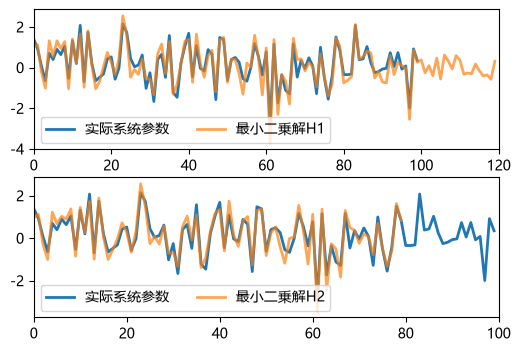

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4))
ax1.plot(h, linewidth=2, label="实际系统参数")
ax1.plot(h_long, linewidth=2, label="最小二乗解H1", alpha=0.7)
ax1.legend(loc="best", ncol=2)
ax1.set_xlim(0, len(h_long))

ax2.plot(h, linewidth=2, label="实际系统参数")
ax2.plot(h_short, linewidth=2, label="最小二乗解H2", alpha=0.7)
ax2.legend(loc="best", ncol=2)
ax2.set_xlim(0, len(h))
plt.show()

## 特征值与特征向量

$n\times n$ 的矩阵 $\mathbf{A}$ 可以看成一个 $n$ 维空间的线性变换：$\mathbf{x}$ 是 $n$ 维向量时，$\mathbf{A} \mathbf{x}$ 就是变换之后的向量。若 $\mathbf{x}$ 是这个变换的特征向量，那么变换之后方向不变，只是长度变了，而长度的倍数就是特征值。用式子写出来如下，其中 $\lambda$ 一般是复数。

$$\mathbf{A} \mathbf{x} = \lambda \mathbf{x}$$

这里用二维的线性变换确认特征值与特征向量的含义：用 `linalg.eig(A)` 计算特征值 `eigvals` 与特征向量 `eigvecs`，其中 `eigvecs` 的每一列就是一个特征向量。

In [8]:
A = np.array([[1, -0.3], [-0.1, 0.9]])
eigvals, eigvecs = linalg.eig(A)
%C eigvals; eigvecs

            eigvals                         eigvecs           
--------------------------------  ----------------------------
[1.13027756+0.j, 0.76972244+0.j]  [[ 0.91724574,  0.79325185],
                                   [-0.3983218 ,  0.60889368]]


下图是变换前后的向量：蓝色箭头是变换前、红色箭头是变换后，粗箭头则是特征向量。特征向量方向不变、只有长度改变，倍数就是特征值，其中一个是 1.13 倍，另一个是 0.77 倍。

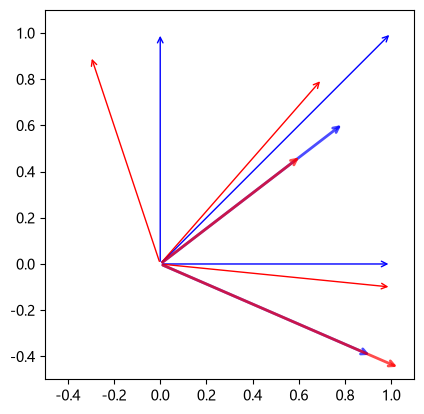

In [9]:
points = np.array([[0, 1.0], [1.0, 0], [1, 1]])


def draw_arrows(points, **kw):
    props = dict(color="blue", arrowstyle="->")
    props.update(kw)
    for x, y in points:
        plt.annotate(
            "",
            xy=(x, y),
            xycoords="data",
            xytext=(0, 0),
            textcoords="data",
            arrowprops=props,
        )


draw_arrows(points)                                            # 変換前
draw_arrows(np.dot(A, points.T).T, color="red")                # 変換後
draw_arrows(eigvecs.T, alpha=0.7, linewidth=2)                 # 特征向量
draw_arrows(np.dot(A, eigvecs).T, color="red", alpha=0.7, linewidth=2)

ax = plt.gca()
ax.set_aspect("equal")
ax.set_xlim(-0.5, 1.1)
ax.set_ylim(-0.5, 1.1)
plt.show()

`numpy.linalg` 里也有 `eig()`，但 `scipy.linalg.eig()` 还能计算广义特征值与广义特征向量，也就是满足下面式子的那一对，其中 $\mathbf{B}$ 是 $n \times n$ 的矩阵。

$$\mathbf{A}\mathbf{x} = \lambda \mathbf{B} \mathbf{x} $$

广义特征向量可以用来拟合椭圆。

```{seealso}
http://research.microsoft.com/pubs/67845/ellipse-pami.pdf

用广义特征向量拟合椭圆的论文
```

椭圆上的点满足下面的式子，其中 $a,b,c,d,e,f$ 是椭圆的参数，$(x, y)$ 是平面上的点。

$$f(x, y) = a x^2 + b x y + c y^2 + d x + e y + f = 0$$

椭圆拟合就是给定点集 $(x_i, y_i)$，找出让 $\sum{f(x_i, y_i)^2}$ 最小的参数。这本身是个最小化问题，用上一章的 `optimize.least_squares()` 也能解，但所有参数都取 0 是一个平凡解，所以需要一些技巧，这里介绍论文中的方法。

先令 $\mathbf{x_i} = [x_i^2, x_i y_i, y_i^2, x_i, y_i, 1]^T$、$\mathbf{D}=[\mathbf{x}_1, \dots ,\mathbf{x}_n]$，其中 $\mathbf{D}$ 是 $n \times 6$ 的矩阵、每一行对应一个点。再令系数为 $\mathbf{a} = [a, b, c, d, e, f]^T$，于是 $\mathbf{a}$ 满足下面的式子。

$$\mathbf{D}^T \mathbf{D} \mathbf{a} = \lambda \mathbf{C} \mathbf{a}$$ 

其中 $\mathbf{C}$ 是 $6 \times 6$ 的矩阵。

$$\mathbf{C} = \begin{bmatrix}
0 &0  &2  &0  &0  & 0\\ 
0 &-1  &0  &0  &0  &0 \\ 
2 &0  &0  &0  &0  &0 \\ 
0 &0 &0  &0  &0  &0 \\ 
0 &0  &0  &0  &0  &0 \\ 
0 &0  &0  &0  &0  &0 
\end{bmatrix}$$

这就是广义特征值的式子，所以能用 `linalg.eig()` 解。下面的代码用椭圆的参数方程生成 60 个点，再加上噪声。

$$X(t)=X_c + a\,\cos t\,\cos \varphi - b\,\sin t\,\sin\varphi$$
$$Y(t)=Y_c + a\,\cos t\,\sin \varphi + b\,\sin t\,\cos\varphi$$

In [10]:
np.random.seed(1)
t = np.random.uniform(0, np.pi * 0.8, 60)

alpha = 0.2
a = 1.5
b = 1.0
x = 1.0 + a * np.cos(t) * np.cos(alpha) - b * np.sin(t) * np.sin(alpha)
y = 1.0 + a * np.cos(t) * np.sin(alpha) + b * np.sin(t) * np.cos(alpha)
x += np.random.normal(0, 0.01, size=len(x))    # 加入噪声
y += np.random.normal(0, 0.01, size=len(y))

❶ 给 `eig()` 传第 2 个参数就会计算广义特征值与特征向量，这里一共得到 6 个特征向量。❷ 把 6 个特征向量分别代入椭圆的式子，算出各点处的误差。❸ 选出误差最小的那个特征向量作为椭圆的参数 `coeffs`。下图是选出的椭圆与原始的点。

In [11]:
D = np.c_[x**2, x * y, y**2, x, y, np.ones_like(x)]
A = np.dot(D.T, D)
C = np.zeros((6, 6))
C[[0, 1, 2], [2, 1, 0]] = 2, -1, 2
eigvals, eigvecs = linalg.eig(A, C)  #❶
eigvecs = np.real(eigvecs)
err = np.max(np.dot(D, eigvecs) ** 2, 0)  #❷
coeffs = eigvecs[:, np.argmin(err)]  #❸
print(coeffs)

[ 0.1688253  -0.07497218  0.4080125  -0.26630829 -0.81768817  0.24468129]


In [12]:
err

array([3.37997734e-02, 5.67187215e-04, 3.00048971e-04, 1.28912218e+00,
       1.51696296e+00, 1.12949412e+00])

确认求出的椭圆确实贴合这些点：用 `contour` 画出 $f(x,y)=0$ 的曲线，椭圆就会落在点上。

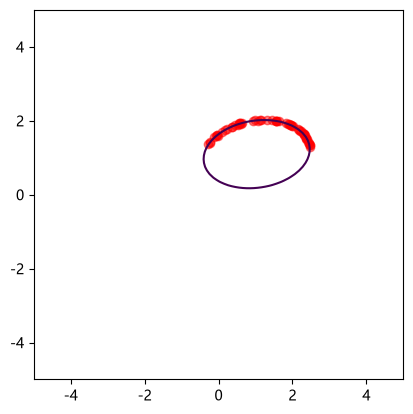

In [13]:
def ellipse(p, x, y):
    a, b, c, d, e, f = p
    return a * x**2 + b * x * y + c * y**2 + d * x + e * y + f


X, Y = np.mgrid[-5:5:100j, -5:5:100j]
Z = ellipse(coeffs, X, Y)
fig, ax = plt.subplots()
ax.set_aspect("equal")
ax.plot(x, y, "ro", alpha=0.5)
ax.contour(X, Y, Z, levels=[0])
plt.show()

## 用最优化拟合椭圆

不用特征值，也可以用最优化来拟合椭圆：把椭圆的参数表示成(长半径, 短半径, 旋转角, 中心的 x, 中心的 y)这 5 个，再让各点处方程值的平均尽量小。

下面的代码给出由这 5 个参数计算 $a,b,c,d,e,f$ 的函数，以及误差函数。

In [14]:
from scipy import optimize


def ellipse_pars(a, b, theta, x0, y0):
    """由(长半径, 短半径, 旋转角, 中心)算出椭圆的系数。"""
    A = a**2 * np.sin(theta) ** 2 + b**2 * np.cos(theta) ** 2
    B = 2 * (b**2 - a**2) * np.sin(theta) * np.cos(theta)
    C = a**2 * np.cos(theta) ** 2 + b**2 * np.sin(theta) ** 2
    D = -2 * A * x0 - B * y0
    E = -B * x0 - 2 * C * y0
    F = A * x0**2 + B * x0 * y0 + C * y0**2 - a**2 * b**2
    return A, B, C, D, E, F


def err(p, x, y):
    """各点处椭圆方程取值的平均，越接近 0 表示拟合得越好。"""
    p2 = ellipse_pars(*p)
    return np.mean(np.abs(ellipse(p2, x, y)))

用 `minimize()` 找这 5 个参数，为了让半径不为负，用约束加上下限。由于这些点只落在椭圆的一段弧上，长半径与短半径互换之后仍表示同一个椭圆，所以得到的解也可能是半径互换、旋转角相差 90 度的形式，表示的椭圆是一样的。

In [15]:
r = optimize.minimize(
    err,
    [3, 3, 0, 1, 1],
    args=(x, y),
    method="SLSQP",
    constraints=[
        dict(type="ineq", fun=lambda p: p[0] - 0.5),
        dict(type="ineq", fun=lambda p: p[1] - 0.5),
    ],
)
print(r)

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.022678386102078493
           x: [ 8.739e-01  1.421e+00  1.696e+00  1.051e+00  1.136e+00]
         nit: 41
         jac: [-4.525e-04  3.221e-02 -6.872e-03 -1.809e-02  2.251e-02]
        nfev: 273
        njev: 41
 multipliers: [ 0.000e+00  0.000e+00]


局部最优化受初始值影响，所以也可以用 `differential_evolution()` 做全局搜索；只要把范围取宽一些，就不必再操心初始值。

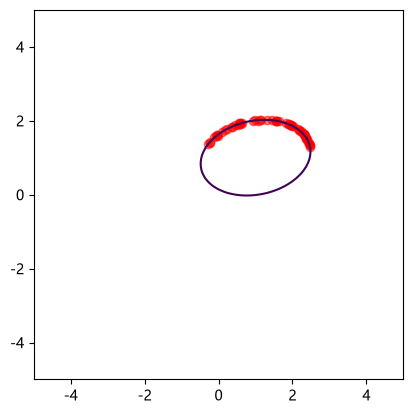

In [16]:
r = optimize.differential_evolution(
    err, bounds=[(1, 10), (1, 10), (-np.pi, np.pi), (-10, 10), (-10, 10)], args=(x, y)
)

X, Y = np.mgrid[-5:5:100j, -5:5:100j]
Z = ellipse(ellipse_pars(*r.x), X, Y)
fig, ax = plt.subplots()
ax.set_aspect("equal")
ax.plot(x, y, "ro", alpha=0.5)
ax.contour(X, Y, Z, levels=[0])
plt.show()

## 奇异值分解

奇异值分解(SVD)把一个矩阵分解成三个矩阵之积，在信号处理与统计里用得很多。设 $\mathbf{M}$ 是 $m \times n$ 的矩阵，则可以分解成 $\mathbf{M} = \mathbf{U} \mathbf{\Sigma} \mathbf{V^{*}}$，其中 $\mathbf{U}$ 是 $m \times m$ 的酉矩阵，$\mathbf{\Sigma}$ 是 $m \times n$ 的对角矩阵，$\mathbf{V^{*}}$ 是 $\mathbf{V}$ 的共轭转置、也是 $n \times n$ 的酉矩阵；$\mathbf{\Sigma}$ 的对角元素就是奇异值，按从大到小排列。

作为例子，这里对一张灰度图像做奇异值分解，再用奇异值较大的部分把图像恢复出来。先读入图像，由红、绿、蓝三个通道合成灰度图像 `img`。

In [17]:
r, g, b = np.rollaxis(plt.imread("data/vinci_target.png"), 2).astype(float)
img = 0.2989 * r + 0.5870 * g + 0.1140 * b
img.shape

(505, 375)

用 `scipy.linalg.svd()` 分解会返回三个结果。

* `U`：式子里的 $\mathbf{U}$
* `s`：式子里的 $\mathbf{\Sigma}$ 的对角元素，由于是对角矩阵，所以以一维数组返回
* `Vh`：式子里的 $\mathbf{V^{*}}$

In [18]:
U, s, Vh = linalg.svd(img)
%C 5 U.shape; s.shape; Vh.shape

 U.shape       s.shape      Vh.shape 
----------     -------     ----------
(505, 505)     (375,)      (375, 375)


`s` 里的每个值对应 `U` 的一列与 `Vh` 的一行，由于按从大到小排列，越靠前的向量对图像的贡献越大。如下图，奇异值的大小相差很多，要注意纵轴是对数刻度。

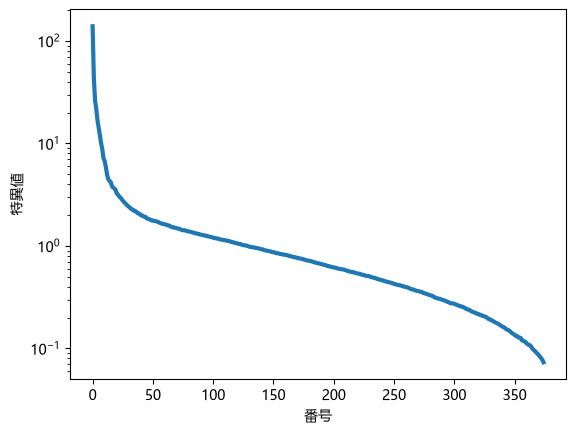

In [19]:
plt.semilogy(s, lw=3)
plt.xlabel("番号")
plt.ylabel("特異値")
plt.show()

下面的 `composite()` 用 `U` 与 `Vh` 中前 n 个向量把矩阵重建出来；如果全部向量都用上，就回到原矩阵。

In [20]:
def composite(U, s, Vh, n):
    """用从大到小的前 n 个奇异值把矩阵重建出来。"""
    return U[:, :n] @ (s[:n, None] * Vh[:n, :])


np.allclose(img, composite(U, s, Vh, len(s)))

True

把用 10 个、20 个、50 个向量重建的图像并排放在一起，用的向量越多，就越接近原图像。

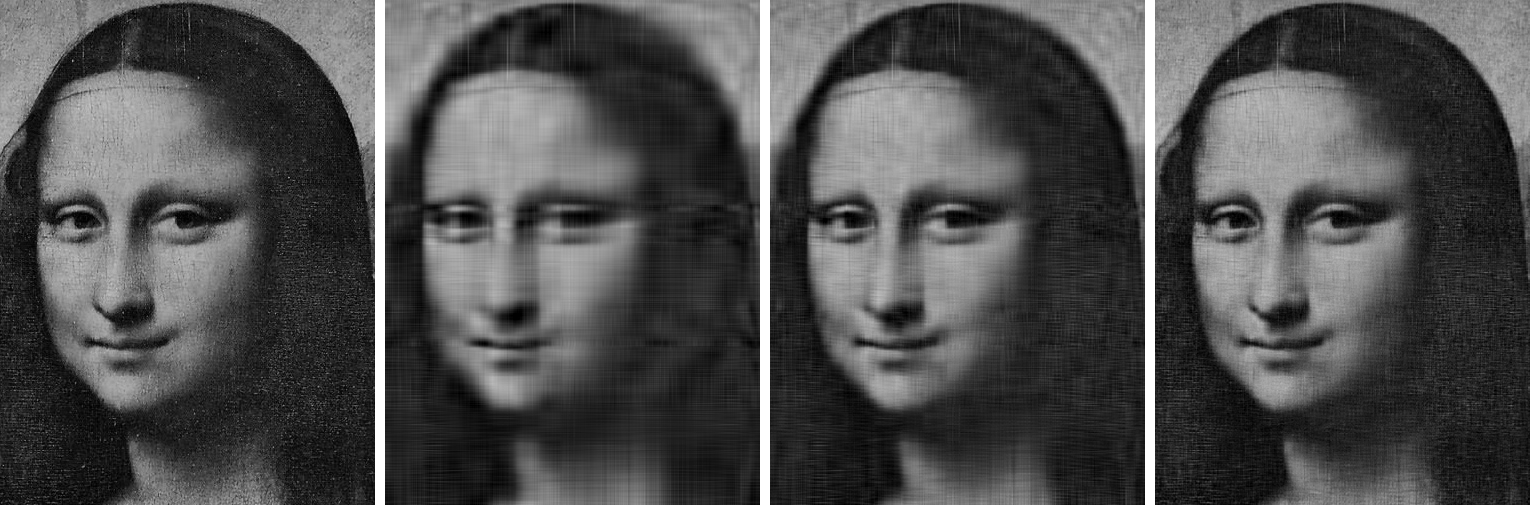

In [21]:
img10 = composite(U, s, Vh, 10)
img20 = composite(U, s, Vh, 20)
img50 = composite(U, s, Vh, 50)

from helper.numpy import array_image

array_image(img, img10, img20, img50)

## 小结

* 线性方程组用 `solve()` 解，比先求逆矩阵再相乘要快。
* 同一个矩阵而有多个右端项时，用 `lu_factor()` 分解、再反复用 `lu_solve()`。
* 矩阵不是方阵、或者式子不够时，用 `lstsq()` 求最小二乘解。
* 特征值用 `eig()` 求，传第 2 个参数就变成广义特征值，可以用在椭圆拟合上。
* 奇异值分解用 `svd()`，只用大奇异值对应的向量，就能压缩图像。